# Get started with Qiskit in the classroom

For this Qiskit in Classrooms module, students must have a working Python environment with the following packages installed:
- `qiskit` v2.1.0 or newer
- `qiskit-ibm-runtime` v0.40.1 or newer
- `qiskit-aer` v0.17.0 or newer
- `qiskit.visualization`
- `numpy`
- `pylatexenc`

To set up and install the packages above, see the [Install Qiskit](https://quantum.cloud.ibm.com/docs/guides/install-qiskit) guide.

**Running in VS Code?** Before running the first cell, open a terminal and install `ipykernel` in the Python environment you'll use (or click *Install* when VS Code prompts you):

```
pip install ipykernel
```

Then select that same environment as the notebook's kernel. You don't need this step in Google Colab or Jupyter.

> **Please don't run this notebook on real quantum hardware.** We recommend saving your free IBM Quantum cloud time for your hackathon project. Everything in this notebook runs on simulators on your own computer.

In [1]:
# Run this cell once to install everything this notebook needs
%pip install --upgrade "qiskit[visualization]" qiskit-ibm-runtime qiskit-aer numpy pylatexenc qc-grader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 3.6 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 8.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qc-grader]/4 [qc-grader]
Note: you may need to restart the kernel to use updated packages.


### Set up your IBM Quantum account (for the grader)

The graded questions at the end of this notebook use your IBM Quantum Platform account to identify you. This does **not** use any of your QPU time.

1. If you don't have an account yet, create a free one at [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com) (the free Open plan is enough) and copy your API key. The [Set up your IBM Cloud account](https://quantum.cloud.ibm.com/docs/guides/cloud-setup) guide walks you through it.
2. Run the cell below, paste your API key into the box that appears, and press Enter.

On your own computer, you only need to do this once. **In Google Colab, rerun this cell every time you start a new session**, because Colab forgets saved accounts when its runtime restarts. Typing your key into the box keeps it out of the notebook, so never paste it directly into a code cell.

In [3]:
# Run once per session so the grader cells can identify you (this does NOT use any QPU time)
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService
from dotenv import load_dotenv
import os
load_dotenv()
api_key = os.getenv("IBM_API_KEY")
crn = os.getenv("IBM_CRN")

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=api_key,
    set_as_default=True,
    overwrite=True,
)

In [4]:
from qc_grader.challenges.fallfest_2026 import check_progress


from qc_grader.challenges.fallfest_2026.intro import (
    grade_intro_ex1, grade_intro_ex2, grade_intro_ex3, grade_intro_ex4,
    grade_intro_ex5, grade_intro_ex6, grade_intro_ex7, grade_intro_ex8,
    grade_intro_ex9, grade_intro_ex10, grade_intro_ex11, grade_intro_ex12,
    grade_intro_ex13, grade_intro_ex14,
)

## Introduction

In the Qiskit in the Classroom modules, you'll have the opportunity to use a quantum computer to explore various concepts in quantum computing-adjacent fields such as quantum mechanics, computer science, chemistry, and more. This module serves as a prerequisite to the others - it introduces the fundamentals of quantum computing and how to use Qiskit to run quantum circuits.

First we'll give you a brief overview of how a classical computer works, then we'll show you how these concepts are adapted to fit the quantum computing paradigm. Finally, we'll show you how to put these concepts together to build and execute your first quantum circuit.

## Classical computers

You're likely familiar with the basics of how classical computers work, so here is a quick recap of the key features that we'll then compare to quantum computers.

### The basic units of information: bits

Classical computers process classical information, and the fundamental unit of classical information is the *bit*. A single bit can store the answer to one "yes/no" question. We usually represent the two binary states of a bit as "0" and "1".

Combining bits enables you to store more information: $N$ bits can be in one of $2^N$ different possible states. For example, four bits can store any number from 0 (`0000`) to 15 (`1111`). Just like digits in base 10, the rightmost bit is the least significant: it is worth $2^0 = 1$, the next bit to the left is worth $2^1 = 2$, then $2^2 = 4$, and so on.

### Fundamental operations: gates

Now, a computer needs to be able to *do* something with the bits in order to, well, compute. Logic gates such as NOT (which flips a bit), AND, OR, and XOR are the fundamental building blocks of all the more complicated algorithms and codes. The effect of a gate can be represented in a so-called "truth table," with columns for the input and output states. We'll need two of these gates below:

**AND** outputs 1 only if both input bits are 1:

| Input | Output |
| :------- | -------: |
| 00      |0  |
| 01  | 0  |
| 10      |0  |
| 11  | 1  |

**XOR** ("exclusive OR") outputs 1 if *only one* of the input bits is 1:

| Input | Output |
| :------- | -------: |
| 00      | 0  |
| 01  | 1  |
| 10      | 1  |
| 11  | 0  |


### Measurements:

Typically, when learning about classical computing, not much attention is paid to the process of reading out the state of the bits. This is because it's not very complex from a conceptual perspective. You can measure the bits at anytime before, during, or after a computation, and it doesn't affect the outcome. This is not the case in quantum computing, as we will discuss below.

### Circuits:

By combining the gates above, you can do any sort of operation you want on a computer. Let's take a simple example: Using the AND and XOR gates, you can construct the half-adder circuit, which calculates the sum of two bits. This is represented in a logical circuit diagram, where the wires represent the bits and the gates operating on the bits are shown as symbols on the corresponding wires:

<img src="https://quantum.cloud.ibm.com/learning/images/modules/quantum-mechanics/get-started-with-qiskit/classicaladder.avif" alt="Classical circuit diagram for the half-adder circuit. An XOR gate generates the Sum output bit and an AND gate generates the Carry output bit." width="300">

*Classical circuit diagram for the half-adder circuit. An XOR gate generates the Sum output bit and an AND gate generates the Carry output bit.*

So, the two bits are copied and fed through both an AND gate and an XOR gate. The result of the XOR gate is the "sum bit" (S), which remains in the ones place of the binary number, and the result of the AND gate is the "carry bit" (C), which is the value of the next most significant digit in the binary number. Here is the truth table:

| $A$ | $B$ | Sum ($A \oplus B$) | Carry ($A \wedge B$) |
|---|---|-------------|----------------|
| 0 | 0 |      0      |       0        |
| 0 | 1 |      1      |       0        |
| 1 | 0 |      1      |       0        |
| 1 | 1 |      0      |       1        |


#### Check your understanding

Verify that the above truth table yields the correct solution for an adder circuit. That is, for each of the four options of A and B, verify that $A+B=S+2 \times C$.

<details>
<summary>Answer</summary>

$$
\begin{aligned}
0+0 &= 0+0 = 0 ~\checkmark \\
0+1 &= 1+0 = 1  ~\checkmark \\
1+0 &= 1+0 = 1  ~\checkmark \\
1+1 &= 0+2 = 2 ~\checkmark \\
\end{aligned}
$$

</details>

## Quantum computers

### Bits $\rightarrow$ qubits

Just as bits are the fundamental units of classical information, *quantum* bits, or "qubits," are the fundamental units of quantum information. Like the classical bit, the state of a qubit can be either 0 or 1, which we typically denote as $\vert 0\rangle$ and $\vert 1\rangle$. But unlike the classical bit, a quantum bit can also be in a *superposition* of both the $\vert 0\rangle$ state and the $\vert 1\rangle$ state at the same time. In general, a qubit can be in any state $\vert \psi\rangle$ of the form:

$$
\vert \psi\rangle = c_0 \vert 0\rangle + c_1 \vert 1\rangle
$$

The numbers $c_0$ and $c_1$ are called *amplitudes*. You can think of them as "how much" of each outcome is in the state: when you measure the qubit, you get 0 with probability $\vert c_0\vert^2$ and 1 with probability $\vert c_1\vert^2$, and these two probabilities always add up to 1.

#### A note on phase

Amplitudes also carry a hidden "sign" called the *phase*: for example, $\frac{1}{\sqrt{2}}(\vert 0\rangle + \vert 1\rangle)$ and $\frac{1}{\sqrt{2}}(\vert 0\rangle - \vert 1\rangle)$ are different states, even though a single measurement can't tell them apart (both give 0 or 1 with 50/50 odds). Phase starts to matter once more gates are applied, because it lets outcomes reinforce or cancel each other, which is a big part of what makes quantum algorithms work.

#### Multiple qubits

While the state of multiple bits could simply be expressed as a string of 0s and 1s, the state of multiple qubits gets a little more interesting because of the principles of *superposition* and *entanglement*.

Recall that $N$ bits could be in one of $2^N$ possible states ranging from binary numbers 000...000 to 111...111. But now, because of the principle of superposition, $N$ *qubits* can be in a superposition of *all* of these states at once! For example, three qubits can be in a superposition of all eight bitstrings

$$
\vert 000\rangle,\ \vert 001\rangle,\ \vert 010\rangle,\ \vert 011\rangle,\ \vert 100\rangle,\ \vert 101\rangle,\ \vert 110\rangle,\ \vert 111\rangle
$$

with each bitstring getting its own amplitude. These bitstrings are known as the "computational basis states" of the quantum system. They are the possible results you can get when you measure all of the qubits.

Each qubit in the system is denoted with an index $0$ through $N-1$. The convention is to read the qubit states from right to left, so that the state of qubit $0$ is the rightmost state and the state of qubit $N-1$ is the leftmost. This is known as "little-endian" notation, and it may seem counterintuitive at first, since we're used to reading left to right.


#### Check your understanding

At first glance, it may seem counterintuitive to order the qubits from right to left as in little-endian notation, but it's actually a very logical thing to do! Explain why. (Recall our discussion above of binary to base-10 number conversion.)

<details>
<summary>Answer</summary>

If we order qubits from right to left, so that qubit 0 is the farthest right and qubit N-1 is the farthest left, It is logical to associate qubit $0$ with the least-significant bit, which is multiplied by $2^0$ and qubit $N-1$ with the most-significant bit, which is multiplied by $2^{N-1}$.

</details>



#### Entanglement

As we mentioned earlier, another key feature of qubits is that they can be *entangled* with one another. Let's take an example of a two-qubit state, where $c_0 = c_3 = \frac{1}{\sqrt{2}}$ and $c_1 = c_2 = 0$:

$$\vert \psi\rangle = \frac{1}{\sqrt{2}}(\vert 00\rangle + \vert 11\rangle)$$

So, the state of qubit 0 can be either $\vert 0\rangle$ or $\vert 1\rangle$ with equal probability, and same with the state of qubit 1. But these probabilities are no longer independent of one another. If we find the state of qubit 0 to be $\vert 0\rangle$, then we *know* that qubit 1 will also be in $\vert 0\rangle$. This is true no matter how far apart the qubits are, which is why the act of measuring an entangled state is sometimes referred to as "spooky action at a distance."

#### Check your understanding

Is the state $\vert \psi\rangle = \vert 11\rangle$ entangled? Why or why not?

<details>
<summary>Answer</summary>

It is not entangled. While the outcomes are always the same when you measure both qubits, this is only because each qubit is always fixed in the state $\vert 1\rangle$. The result of measuring one qubit does not actually depend on the other — both are just always $\vert 1\rangle$.

</details>

## Gates $\rightarrow$ quantum gates

Just as classical gates such as NOT, AND, OR, and XOR can be combined to build arbitrary classical circuits, quantum gates play the same role in quantum computing. Because qubits can be in superpositions, quantum gates are correspondingly richer. We can still describe what a gate does to the basis states $\vert 0\rangle$ and $\vert 1\rangle$ with a truth table, and when a qubit is in a superposition, the gate acts on each part of it. (Under the hood, Qiskit keeps track of all of this with linear algebra, but you won't need to do that math yourself in this module.)

Below we will introduce the most common quantum gates and how they transform the qubits they interact with. When applicable, we'll connect them back to familiar classical gates.

### Single-qubit gates

**$X$ gate**: This is the quantum equivalent of a NOT operation. Its truth table looks exactly like the classical NOT gate:

| Input | Output |
| :------- | -------: |
| $\vert 0\rangle$      | $\vert 1\rangle$  |
| $\vert 1\rangle$  | $\vert 0\rangle$  |

In Qiskit, creating a circuit with an $X$ gate looks like this:

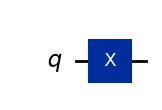

In [7]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.x(0)
qc.draw("mpl")

In this very simple circuit diagram, the qubit is represented by a wire, the black horizontal line, and the gate shows up as a box on that wire.

__Hadamard gate:__ Creates a superposition state. If you measure a qubit right after a Hadamard gate, you get 0 or 1 with 50/50 odds. Truth table:

| Input | Output |
| :------- | -------: |
| $\vert 0\rangle$      | $\frac{1}{\sqrt{2}}\left(\vert 0\rangle+\vert 1\rangle\right)$  |
| $\vert 1\rangle$  | $\frac{1}{\sqrt{2}}\left(\vert 0\rangle-\vert 1\rangle\right)$  |


A circuit with a Hadamard gate is made as follows:

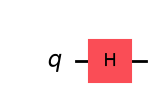

In [8]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.h(0)
qc.draw("mpl")

**Phase gates ($Z$ and $T$)**: These gates leave $\vert 0\rangle$ alone and change only the phase of $\vert 1\rangle$. On their own, they don't change the measurement probabilities, but they change how the qubit behaves under later gates. The $Z$ gate flips the sign of $\vert 1\rangle$ (a half turn of the phase, $\pi$). The $T$ gate is a smaller version that turns the phase of $\vert 1\rangle$ by one-eighth of a full turn ($\pi/4$):

| Input | $Z$ output | $T$ output |
| :------- | :-------: | -------: |
| $\vert 0\rangle$      | $\vert 0\rangle$  | $\vert 0\rangle$  |
| $\vert 1\rangle$  | $-\vert 1\rangle$  | $\vert 1\rangle$ with its phase turned by $\pi/4$  |

In Qiskit, here is a circuit with a $Z$ gate on qubit 0 and a $T$ gate on qubit 1:

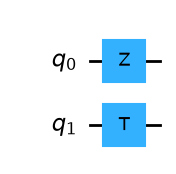

In [9]:
qc = QuantumCircuit(2)
qc.z(0)
qc.t(1)
qc.draw("mpl")

### Multi-qubit gates

Two-qubit gates can resemble classical two-bit gates, but with one important caveat: all quantum gates must be reversible. Two input qubits always map to two output qubits, and the operation can, in principle, be undone. This stands in contrast to the classical gates we saw above such as AND or OR, which lose information and are irreversible — given an output, you cannot uniquely determine the input.

__CNOT (Controlled-NOT) gate:__ The two input qubits are called the "control" and "target" qubits. The control qubit remains unchanged, but its state dictates what happens to the target qubit. If the control qubit is in the state $\vert 1\rangle$, then an $X$ gate is applied to that target; if the state of the control qubit is $\vert 0\rangle$, then no change is made. In the notation below, assume the qubit $A$ (rightmost qubit) is the control, and qubit $B$ (the leftmost qubit) is the target. Below, the notation used is $CNOT(q_{control},q_{target})\vert BA\rangle.$

$$CNOT(A,B)\vert BA\rangle_{input} = \vert BA\rangle_{output}$$

| Input | Output |
| :------- | -------: |
| $\vert 00\rangle$      | $\vert 00\rangle$  |
| $\vert 01\rangle$      | $\vert 11\rangle$  |
| $\vert 10\rangle$      | $\vert 10\rangle$  |
| $\vert 11\rangle$      | $\vert 01\rangle$  |

In Qiskit, a CNOT with $q_0$ as control and $q_1$ as target looks like this:

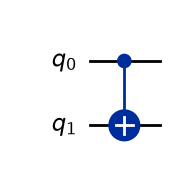

In [10]:
qc = QuantumCircuit(2)
qc.cx(0, 1)
qc.draw("mpl")

This is the first circuit diagram we see with two qubits, which are represented by the two wires. The CNOT gate is implemented between the two qubits, with $q_0$ as control and $q_1$ as target.

#### Check your understanding

For two-qubit gates, qubit ordering conventions suddenly matter. Texts that order qubits $\vert q_0,q_1,...\rangle$ (left to right) will describe the CNOT differently than Qiskit does. Using the truth table above, predict what the CNOT in this circuit does to the state $\vert 01\rangle$. Then run the next cell to check your prediction with Qiskit.

<details>
<summary>Answer</summary>

In Qiskit's little-endian ordering, $\vert 01\rangle$ means $q_1 = 0$ and $q_0 = 1$. The control qubit $q_0$ is 1, so the target $q_1$ is flipped, giving $\vert 11\rangle$. The cell below should print `{'11': 1.0}`, meaning a measurement would give `11` every time.

</details>

In [11]:
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(2)
qc.cx(0, 1)

# Start in |01>, apply the circuit, and ask Qiskit for the outcome probabilities
start = Statevector.from_label("01")
print(start.evolve(qc).probabilities_dict())

{np.str_('11'): np.float64(1.0)}


`Statevector` lets Qiskit do the math for you: it starts from the state you choose, applies the circuit, and reports the probability of each measurement outcome. This is a handy way to check small circuits on your laptop before running them on a real quantum computer.

__SWAP gate:__ This gate swaps the states of two qubits. Truth table:


| Input | Output |
| :------- | -------: |
| $\vert 00\rangle$      | $\vert 00\rangle$  |
| $\vert 01\rangle$      | $\vert 10\rangle$  |
| $\vert 10\rangle$      | $\vert 01\rangle$  |
| $\vert 11\rangle$      | $\vert 11\rangle$  |

In Qiskit:

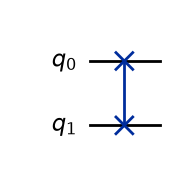

In [12]:
qc = QuantumCircuit(2)
qc.swap(0, 1)
qc.draw("mpl")

The SWAP gate can actually be constructed from three CNOTs. To see how, we can `decompose()` the gate with Qiskit:

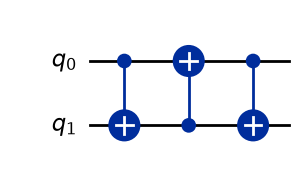

In [13]:
qc = QuantumCircuit(2)
qc.swap(0, 1)
qc.decompose().draw("mpl")

Here we see for the first time how multiple gates are shown in a circuit diagram. We read it from left to right, so the leftmost gate is applied first. So a SWAP is really three CNOTs in a row, and `decompose()` is a handy way to see what any gate is built from.


__Toffoli gate (or "controlled-controlled-NOT" (CCNOT)):__ This is a *three*-qubit gate. The name "controlled-controlled-NOT" may already tell you how it works: there are two control qubits and one target qubit, and the state of the target qubit is flipped only if *both* control qubits are in the state $\vert 1\rangle$. Using the same ordering convention as the CNOT (qubits $A$ and $B$ are the controls, $C$ is the target, written $\vert CBA\rangle$), the truth table is:

| Input | Output |
| :------- | -------: |
| $\vert 000\rangle$      | $\vert 000\rangle$  |
| $\vert 001\rangle$      | $\vert 001\rangle$  |
| $\vert 010\rangle$      | $\vert 010\rangle$  |
| $\vert 011\rangle$      | $\vert 111\rangle$  |
| $\vert 100\rangle$      | $\vert 100\rangle$  |
| $\vert 101\rangle$      | $\vert 101\rangle$  |
| $\vert 110\rangle$      | $\vert 110\rangle$  |
| $\vert 111\rangle$      | $\vert 011\rangle$  |

In Qiskit:

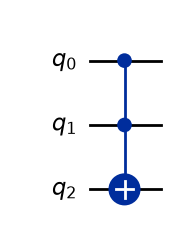

In [14]:
qc = QuantumCircuit(3)
qc.ccx(0, 1, 2)
qc.draw("mpl")

The Toffoli gate, too, can be built from CNOTs, along with some single-qubit gates. However, it is significantly more complicated than the SWAP gate decomposition, so it will be left as an optional exercise at the end of the module.

## Measurements

Measurements play a special role in quantum computing — one that has no classical computing analog. While in classical computing, you can check your bits at any point of your choosing during an algorithm, in quantum computing, you must be very selective about when to look at your qubits because measurement collapses their state and destroys the superposition that gives qubits their computational complexity.

In particular, when you measure qubits that are in a superposition, they collapse to one of the computational basis states (one bitstring), and the probability of getting each bitstring is the squared size of its amplitude, $\vert c_i\vert^2$. For example, a qubit measured right after a Hadamard gate collapses to 0 about half the time and 1 the other half.

But this destructive effect of a measurement isn't always a hindrance. It is in fact a key resource in certain algorithms and protocols, such as [quantum teleportation](https://quantum.cloud.ibm.com/learning/modules/computer-science/quantum-teleportation) and [quantum key distribution](https://quantum.cloud.ibm.com/learning/modules/computer-science/quantum-key-distribution).

In Qiskit, when a measurement is made, it is sent to a classical register where it is stored as a classical bit. Creating a circuit with a measurement looks like this:

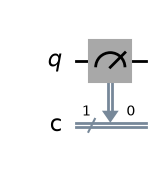

In [17]:
qc = QuantumCircuit(
    1, 1
)  # the second number is the number of classical bits in the circuit
qc.measure(0, 0)
qc.draw("mpl")

## Circuits

Now that we know how qubits, gates, and measurements work, let's make and execute our own quantum circuit! For this, we'll need to introduce you to a useful workflow called Qiskit patterns.

### Qiskit patterns framework

The Qiskit patterns framework is a general procedure for approaching and solving problems with a quantum computer. It consists of four steps:

1. **Mapping** our problem to quantum circuits and operators
2. **Optimizing** the circuit for target hardware
3. **Executing** on target hardware
4. **Post-processing** our results

To illustrate these steps, we will implement a *quantum* version of the half-adder circuit discussed above.

#### 1. Mapping

The classical adder circuit uses an XOR and an AND gate to calculate the sum and carry bits, respectively. We can adapt these gates to the quantum context to make the quantum half adder. First, remembering that quantum gates are *reversible*, we cannot simply overwrite the inputs. Instead, we introduce two helper qubits initialized to $\vert 0\rangle$ to store the sum and carry outputs. So, our full quantum state will consist of qubits $A$ and $B$, and the sum and carry qubits, which we'll label $S$ and $C$:

$\vert \psi\rangle = \vert C S B A\rangle$

Now, we need quantum gates that accomplish what the XOR and AND gates did in the classical circuit.

**Sum:**

For the XOR, we apply two CNOTs, each with control qubits $A$ and $B$ and target qubit $S$ for both. If $A$ and $B$ are different, then one of the CNOT gates will flip $S$ to the $\vert 1\rangle$ state. If $A$ and $B$ are both $\vert 0\rangle$, then nothing happens to $S$ and it remains in the $\vert 0\rangle$ state. If $A$ and $B$ are both $\vert 1\rangle$, then the state of $S$ will flip twice, bringing it back to the $\vert 0\rangle$ state.



**Carry:**

For the carry bit, we need something that works like the classical AND gate.


#### Check your understanding

Look back through the gates we've discussed to see if you can guess which quantum gate we'll use in place of the classical AND gate:

<details>
<summary>Answer</summary>

It's the Toffoli gate! Remember, the Toffoli, or controlled-controlled-NOT gate, flips the target state if and only if control qubit 0 AND control qubit 1 are both $\vert 1\rangle$. So, if the target qubit starts in the state $\vert 0\rangle$, then it has the same action as the AND gate.

</details>


So, now we have all the ingredients we need to make the quantum circuit:

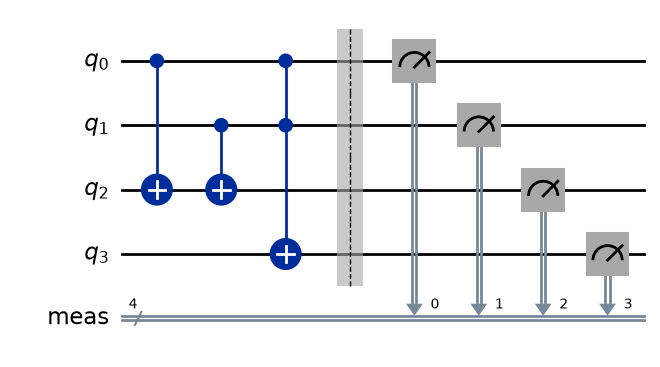

In [18]:
# qubits: a, b, sum, carry
qc = QuantumCircuit(4)

# Choose values for A and B:
a = 0
b = 0

# Prepare A and B qubits according to selected values:
if a:
    qc.x(0)
if b:
    qc.x(1)

# XOR (sum) into qubit 2
qc.cx(0, 2)
qc.cx(1, 2)

# AND (carry) into qubit 3
qc.ccx(0, 1, 3)  # a AND b

# measure
qc.measure_all()


qc.draw("mpl")

Above is the circuit diagram for the quantum half-adder circuit. As mentioned previously, the wires represent qubits $0$ to $3$ ordered from top to bottom, and the classical bit register is the bottom double-lined wire. Then, reading from left to right, we see how the gates are applied to each qubit by seeing where the boxes show up on the corresponding wires. Finally, the measurements are shown at the end. The measurements collapse the qubit states into definite $0$ or $1$ values, and the results are sent to a classical register.

#### 2. Optimizing:

Next, we need to optimize the circuit to be run on the quantum hardware. This optimization is accomplished through the transpiler, which translates the abstract circuit shown above into instructions that the quantum computer will understand. It assigns the logical qubits above to real, physical qubits on the processor and rewrites the gates in terms of its own native set of gates that have been optimized to run on the quantum computer. It can also apply *error suppression* techniques that reduce the effect of noise. To learn more, see Olivia Lane's course, [Quantum Computing in Practice](https://quantum.cloud.ibm.com/learning/courses/quantum-computing-in-practice/introduction).

To save real hardware time for the hackathon, we'll use `FakeFez`: a simulator that mimics a real 156-qubit IBM quantum computer, including its qubit layout, native gates, and noise. The Qiskit patterns steps are exactly the same as they would be on a real device.

In [19]:
# Use FakeFez, a simulated copy of a real IBM quantum computer (including its noise)
from qiskit_ibm_runtime.fake_provider import FakeFez

backend = FakeFez()
print(backend.name)

fake_fez


Now, we use the transpiler to optimize the circuit. We can choose the optimization level from 0 (no optimization) to 3 (highest optimization). To see what each level entails, visit the [Set transpiler optimization level](https://quantum.cloud.ibm.com/docs/guides/set-optimization) guide. The resulting circuit will look significantly different from the logical circuit we made in our mapping step.

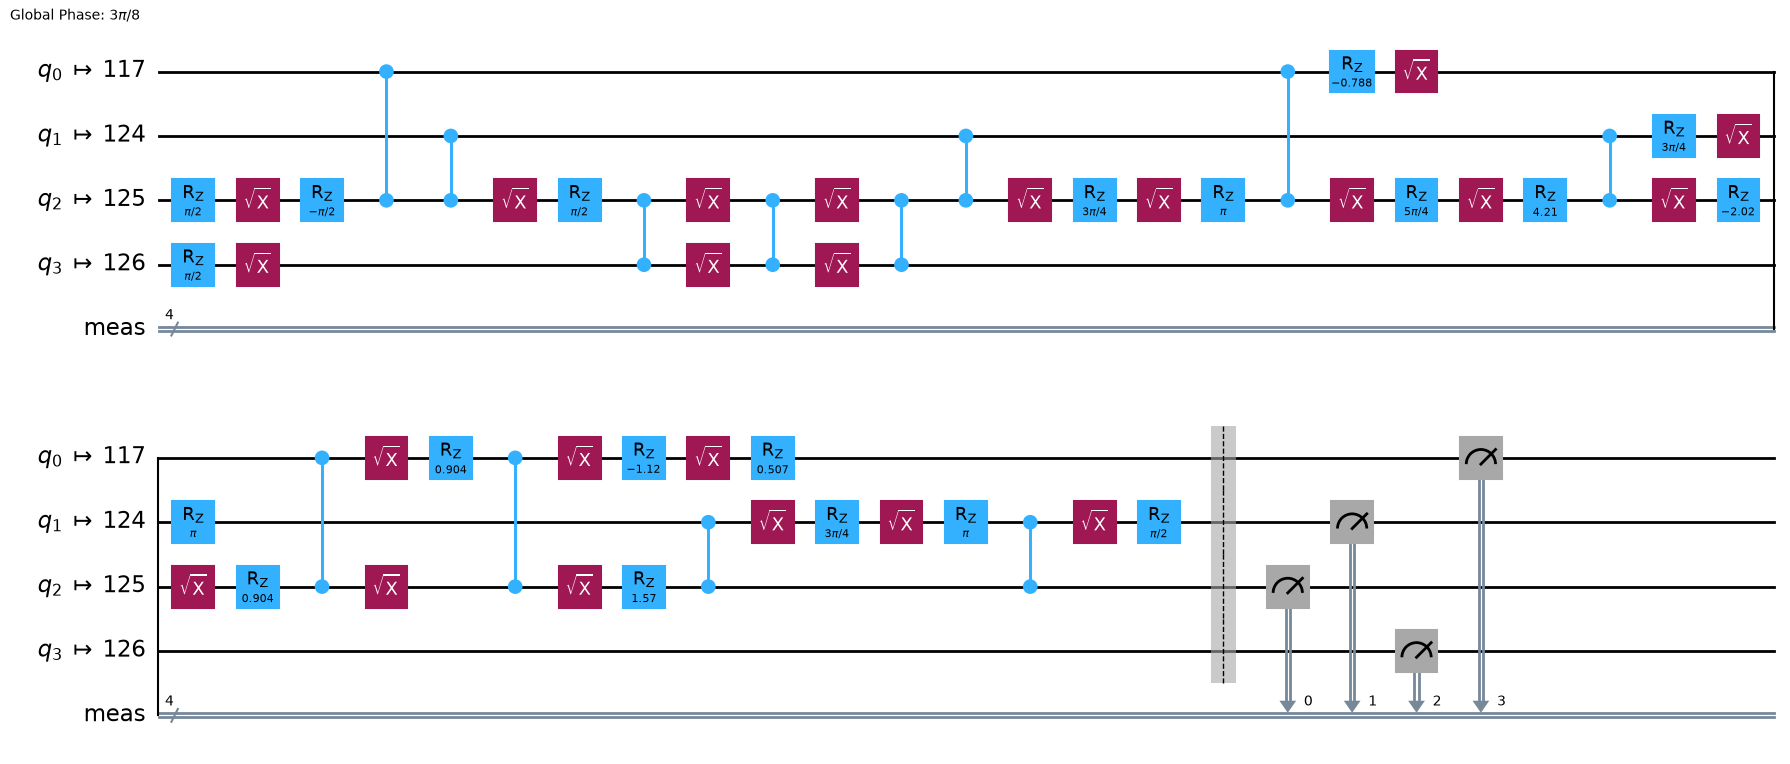

In [20]:
# Transpile the circuit and optimize for running on the quantum computer selected
# Step 2: Transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)
qc_isa = pm.run(qc)

qc_isa.draw("mpl")

A "Sampler" is a primitive designed to sample possible states resulting from a quantum circuit, and collect statistics on what states might be measured and with what probability. We import the Qiskit Runtime Sampler here. Because our backend is a simulator, the Sampler runs the circuit locally on your computer, not in the cloud:

In [21]:
# Load the Sampler primitive (runs locally, since the backend is a simulator)
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)

#### 3. Executing

After preparing the circuit, we can now run it on our simulated quantum computer!

In [22]:
job = sampler.run([qc_isa], shots=100)
res = job.result()
counts = res[0].data.meas.get_counts()

#### How this would look on real hardware (read only, please don't run this here)

For this event, **please don't run this notebook on real hardware**: save your free IBM Quantum time for your hackathon project. But it's worth seeing how little changes when you do move to a real device. Only the backend changes; the transpile and execute steps stay exactly the same.

First, you'd save your IBM Quantum credentials once (see [Set up your IBM Cloud account](https://quantum.cloud.ibm.com/docs/guides/cloud-setup) and [Initialize the service in an untrusted environment](https://quantum.cloud.ibm.com/docs/guides/cloud-setup-untrusted)). Never share a notebook with your API key in it: delete these lines after saving.

```python
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(channel="ibm_quantum_platform",
    instance="<YOUR_IBM_INSTANCE_CRN>", token="<YOUR-API_KEY>", overwrite=True, set_as_default=True)
```

Then you'd pick a real backend instead of `FakeFez`, and run the same Qiskit patterns steps:

```python
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

service = QiskitRuntimeService()                   # load your saved credentials
backend = service.least_busy(operational=True)     # or service.backend("<backend name>")

# Optimize: transpile for this specific device
pm = generate_preset_pass_manager(target=backend.target, optimization_level=3)
qc_isa = pm.run(qc)

# Execute: send the job to the real quantum computer (it waits in a queue and uses your QPU time)
sampler = Sampler(mode=backend)
job = sampler.run([qc_isa], shots=100)
counts = job.result()[0].data.meas.get_counts()
```

These are shown as text blocks rather than code cells on purpose, so they can't be run by accident.

#### 4. Post-processing

Now we're ready to view our results! We'll display a histogram of the 100 samples of the circuit.

counts =  {'0001': 2, '0000': 95, '0100': 2, '1000': 1}


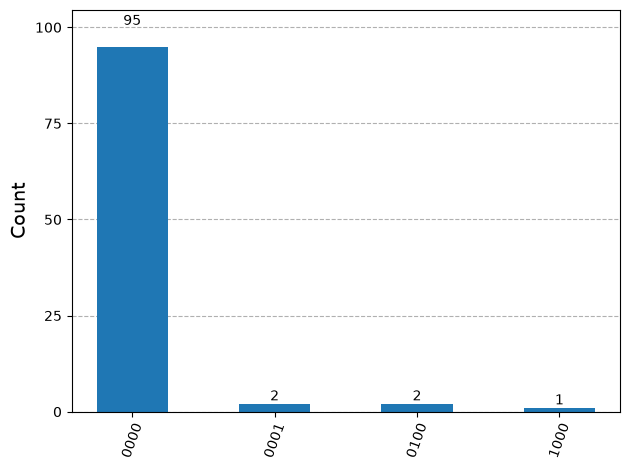

In [23]:
from qiskit.visualization import plot_histogram

print("counts = ", counts)
plot_histogram(counts)

The above histogram shows the measurement results of all four qubits at the end of the circuit. An ideal quantum computer with zero noise would have measured the qubits to have the same values every time, but in reality, noise will cause some of the runs to produce errors.

#### Check your understanding

Using the bitstring with the most counts as your values for $A$, $B$, $S$, and $C$, verify that the quantum adder circuit worked.

<details>
<summary>Answer</summary>

We need to verify that $A+B = S+2 \times C$. Remember that the bitstring order follows little-endian notation, so it is read `CSBA`.

From the histogram above, we see that the `0000` bitstring is the dominant one.

$$0 + 0 = 0 + 0 \times 2 = 0 ~\checkmark$$

</details>



Go back and change the values of $A$ and $B$ to $A=1$ and $B=1$ and go through the Qiskit patterns steps again to rerun the circuit. Verify that the adder circuit worked again.

<details>
<summary>Answer</summary>

You should obtain a histogram with the dominant bitstring being `1011`:

$$1 + 1 = 0 + 1 \times 2 = 2 ~\checkmark$$

</details>

One of the added features of the *quantum* half-adder over the classical half-adder is that it can run with *quantum* inputs. That is, it can "add" qubits $A$ and $B$ even if they are in superposition states. In the Challenge Questions section below, you will be asked to prepare the qubits in superpositions and see what happens!

## Conclusion

This module was designed to give you a firm foundational understanding of the basic principles behind quantum computing by comparing it to classical computing. We looked at the classical half-adder circuit and then showed you how to adapt the circuit to run with qubits on a quantum computer. Now you're ready to explore the other Qiskit in the Classroom modules!

### Critical concepts:

- In contrast to classical bits which can only take on values 0 and 1, qubits can also be in **superposition** states of both 0 and 1.
- Multiple qubits can be in a superposition over the classically allowed bitstrings called **computational basis states**.
- Multiple qubits can be **entangled** so that the state of one depends on the state of the other.
- The Qiskit convention is to use **little-endian notation**, which places the least significant qubit, $q_0$, in the rightmost position and the most significant qubit, $q_N$, leftmost.
- **Quantum gates** are reversible operations that change the state of one or more qubits. Gates like $X$, $H$, CNOT, and Toffoli are the building blocks of quantum circuits, and `Statevector` lets you check what a small circuit does before you run it.
- **Measurements** collapse a quantum superposition state into one of its classically allowed states, with probability equal to the square of the amplitude of the corresponding computational basis state in the superposition.
- Quantum circuits are often represented using **quantum circuit diagrams**, where qubits are depicted as horizontal wires, and quantum gates appear along these wires from left to right.
- To run a quantum circuit, we use the four steps in the **Qiskit patterns** workflow: **Map**, **Optimize**, **Execute**, **Post-process**.

## Questions

### True/False Questions

**1.** A single bit in a classical computer can only hold the value 0 or 1.

In [24]:
answer = True  # Replace with True or False
grade_intro_ex1(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-11-13 18:33:37,793: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! A single bit can only hold 0 or 1.
You scored 1 on this exercise.


**2.** Entanglement means the state of one qubit is independent of the state of another.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex2(answer)

**3.** Quantum gates are generally irreversible operations.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex3(answer)

**4.** The Qiskit convention places the least significant qubit, $q_0$, at the leftmost position.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex4(answer)

**5.** Measuring a quantum state always gives the exact same result if repeated many times.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex5(answer)

**6.** The Hadamard gate creates superposition in a single qubit.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex6(answer)

**7.** Quantum circuits may include measurement operations that collapse the superposition state into one of the classically allowed states.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex7(answer)

**8.** The number of possible classical states for $N$ bits is $2N$.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex8(answer)

**9.** The outcome probabilities for quantum measurements are given by the squared amplitudes of the classically measurable basis states.

In [ ]:
answer = True  # Replace with True or False
grade_intro_ex9(answer)

### Short Answer Questions

**1.** What are some primary differences between a bit and a qubit?

In [ ]:
answer = """Type your answer here"""
grade_intro_ex10(answer)

**2.** What happens to a quantum state when it is measured?

In [ ]:
answer = """Type your answer here"""
grade_intro_ex11(answer)

**3.** Why do we use little-endian notation in Qiskit?

In [ ]:
answer = """Type your answer here"""
grade_intro_ex12(answer)

**4.** What are the four steps in the Qiskit patterns workflow?

In [ ]:
answer = """Type your answer here"""
grade_intro_ex13(answer)

### Challenge Questions

**1.** In the module, we only used the adder to add classically allowed states for $A$ and $B$. But we can also prepare $A$ and $B$ in superpositions! Change the code to prepare each qubit in an equal superposition of 0 and 1, then run the new circuit and obtain a new histogram. What do you see? Explain what is happening.

In [ ]:
answer = """Type your answer here"""
grade_intro_ex14(answer)

**2.** Toffoli gate decomposition. Use `decompose()` to show how the Toffoli gate is built from single- and two-qubit gates. How many CNOTs does it use? Then use `Statevector` (as in the CNOT example above) to check that the decomposed circuit still behaves like a Toffoli for a few input states, such as $\vert 011\rangle$ and $\vert 111\rangle$.

In [ ]:
# Your code for Challenge Question 2 here


In [ ]:
check_progress("intro")